In [1]:
# EXERCICE 4 : CNN sur Fashion-MNIST

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
print(x_train.shape, y_train.shape)

(60000, 28, 28) (60000,)


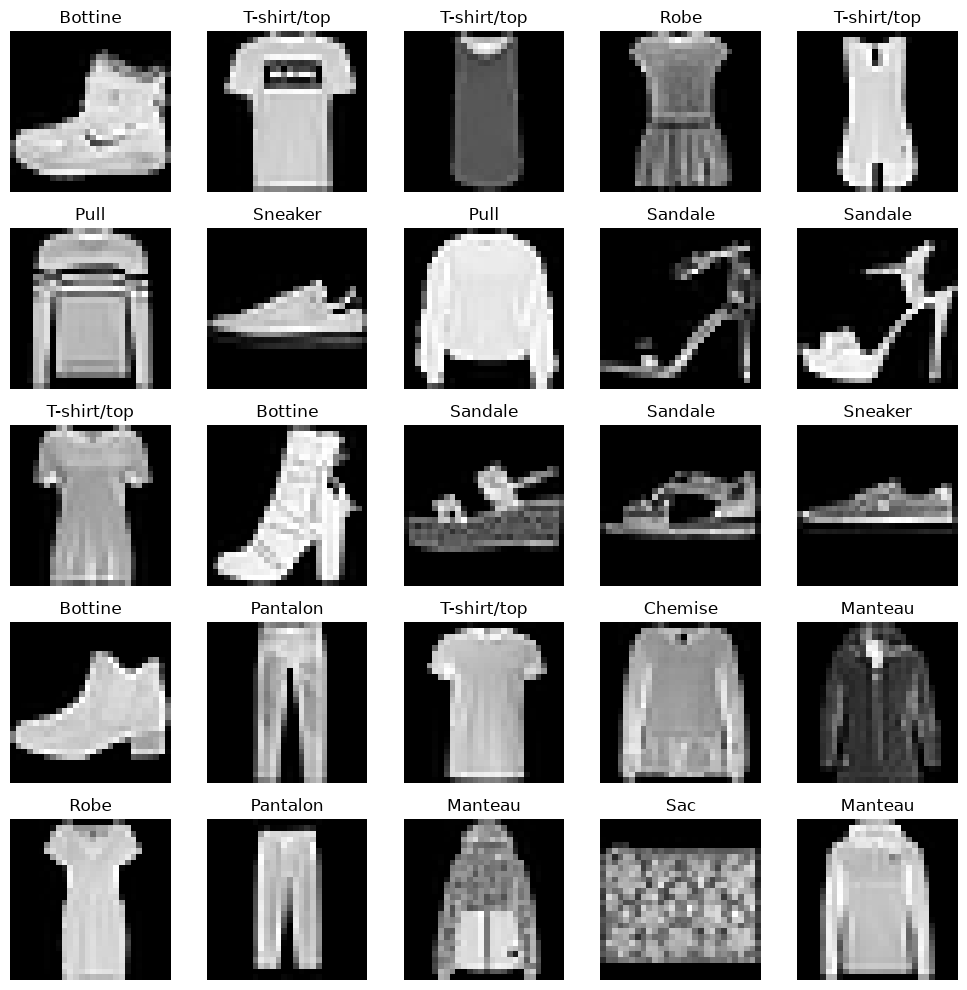

In [4]:
classes = ["T-shirt/top", "Pantalon", "Pull", "Robe", "Manteau",
           "Sandale", "Chemise", "Sneaker", "Sac", "Bottine"]

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5,5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(classes[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

In [5]:
# Etape normalisation
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [6]:
#Etape Ajout de canal
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, - 1)
print("Formes finales :", x_train.shape,x_test.shape)

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


In [7]:
# Étape  : Construire le CNN
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

In [8]:
# Étape : Compiler
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [9]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.7580 - loss: 0.6603 - val_accuracy: 0.8482 - val_loss: 0.3996
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8537 - loss: 0.4083 - val_accuracy: 0.8795 - val_loss: 0.3218
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8776 - loss: 0.3413 - val_accuracy: 0.8892 - val_loss: 0.2978
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8886 - loss: 0.3116 - val_accuracy: 0.8940 - val_loss: 0.2834
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8991 - loss: 0.2816 - val_accuracy: 0.9010 - val_loss: 0.2737
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9067 - loss: 0.2627 - val_accuracy: 0.9028 - val_loss: 0.2570
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9129 - loss: 0.2438 - val_accuracy: 0.9022 - val_loss: 0.2659
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9171 - loss: 0.2274 - val_accurac

In [10]:
# Étape : Évaluer sur le test

loss, acc = model.evaluate(x_test, y_test, verbose=2)
print(f"\nPrécision sur le test: {acc*100:.2f}%")

313/313 - 1s - 3ms/step - accuracy: 0.9095 - loss: 0.2611

Précision sur le test: 90.95%


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


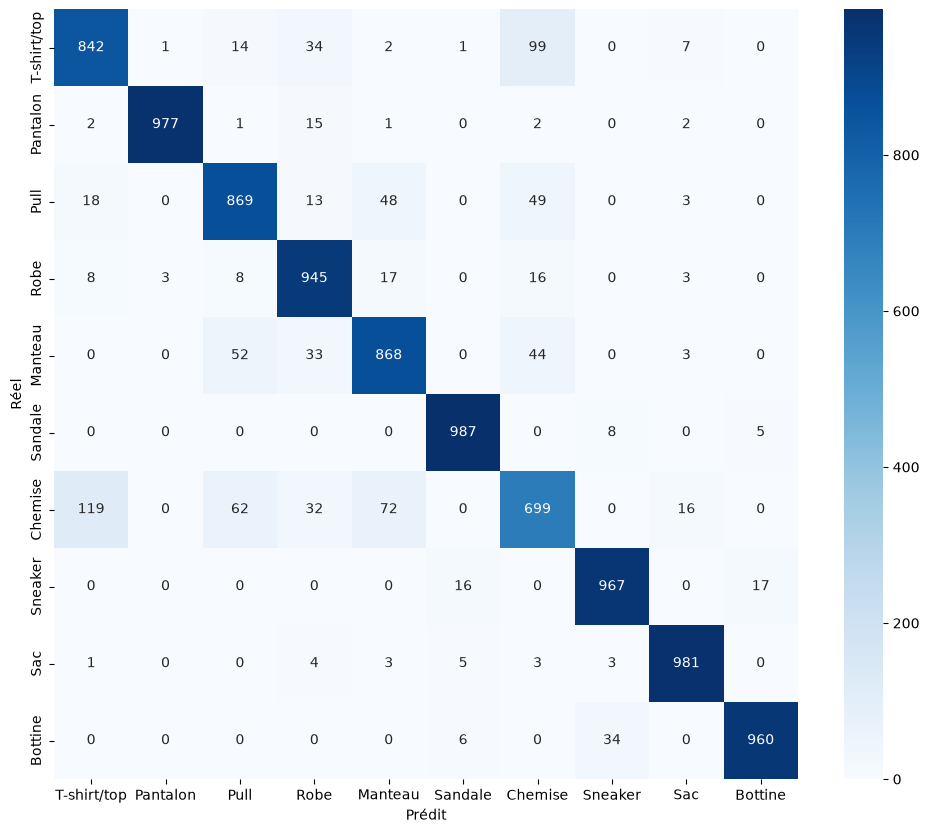

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.84      0.85      1000
    Pantalon       1.00      0.98      0.99      1000
        Pull       0.86      0.87      0.87      1000
        Robe       0.88      0.94      0.91      1000
     Manteau       0.86      0.87      0.86      1000
     Sandale       0.97      0.99      0.98      1000
     Chemise       0.77      0.70      0.73      1000
     Sneaker       0.96      0.97      0.96      1000
         Sac       0.97      0.98      0.97      1000
     Bottine       0.98      0.96      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



In [11]:
y_pred = np.argmax(model.predict(x_test), axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

print(classification_report(y_test, y_pred, target_names=classes))